C:\Users\HOASEN\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


[   0.0 min] OBS: load + detect
[   0.7 min] OBS done | land 5748 | events 257117 | N light 0.257 heavy 0.275 /cell/yr
[   0.7 min] islands: 143 shapes from islands.shp
1981-2014 (34 yr) | El Nino (DJF >= 0.5): [1983, 1987, 1988, 1992, 1995, 1998, 2003, 2005, 2007, 2010] | La Nina (DJF <= -0.5): [1984, 1985, 1989, 1996, 1999, 2000, 2001, 2006, 2008, 2009, 2011, 2012]


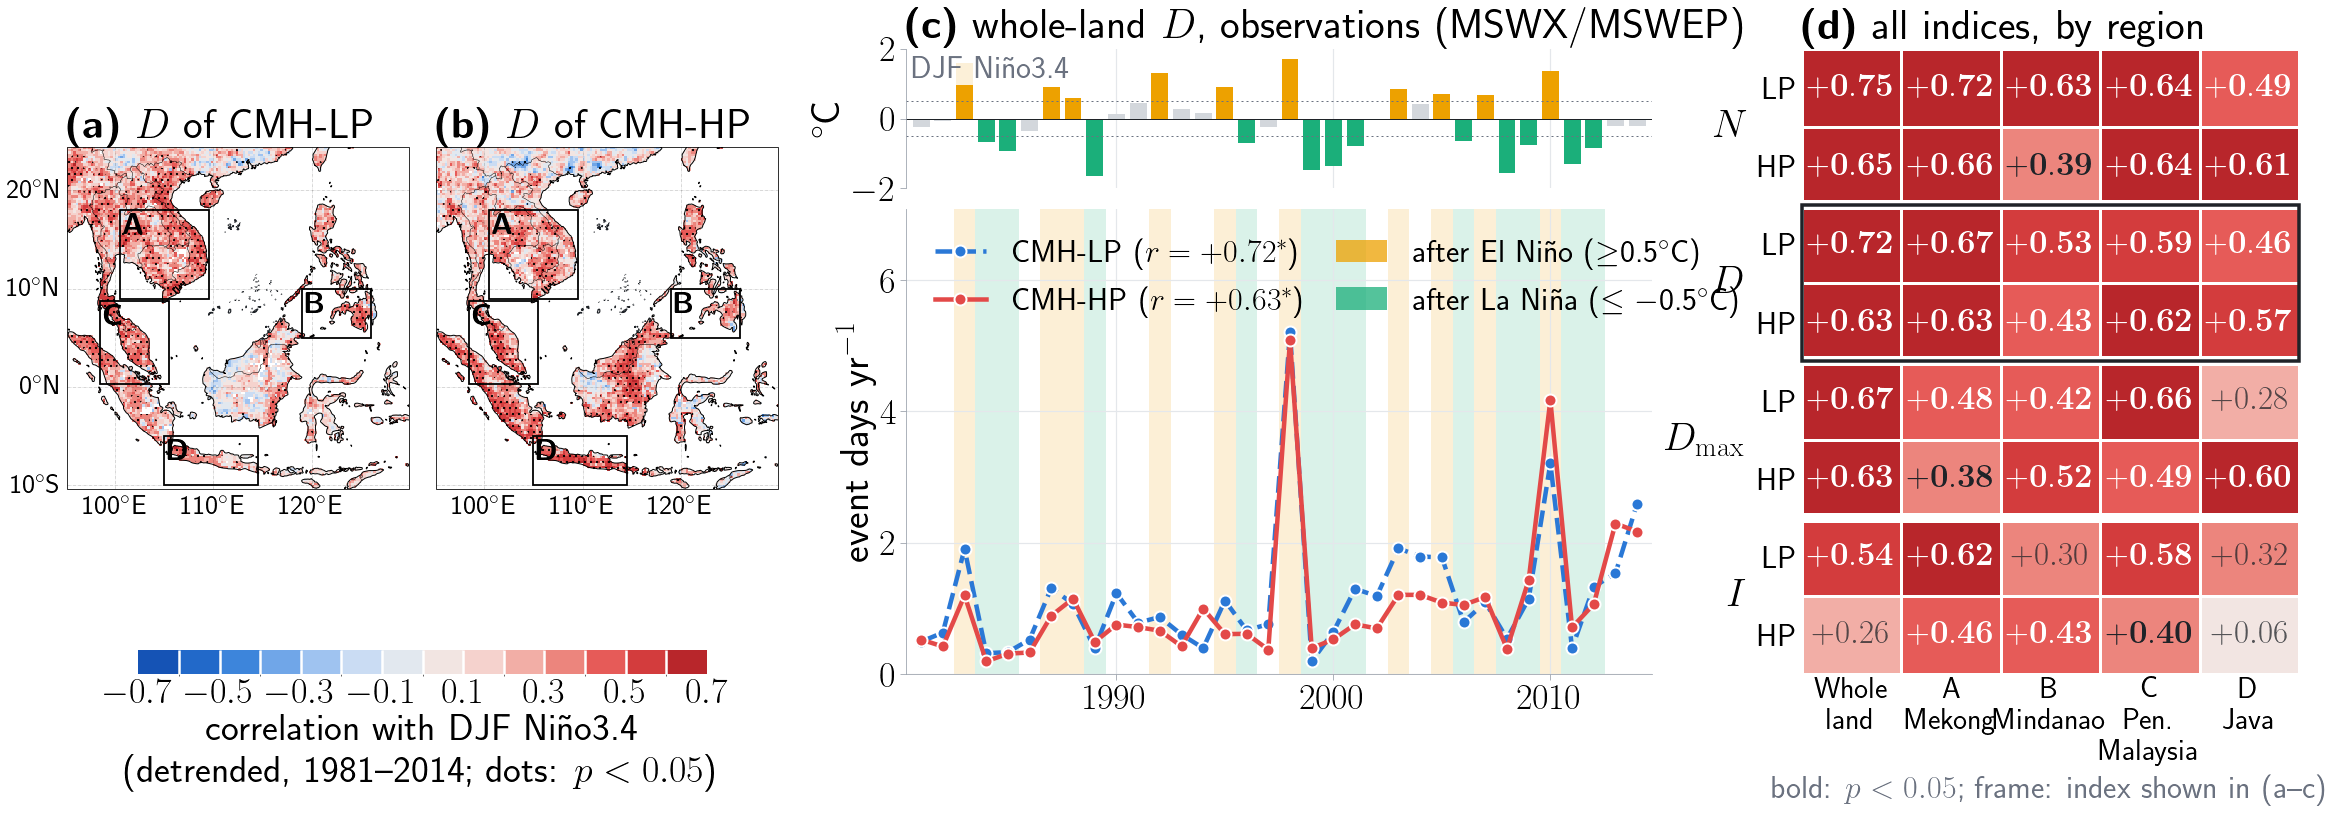


detrended r with DJF Nino3.4 (OBS, 1981-2014; * p<0.05; n/a: fewer than 10 years with events)
           Whole land A Mekong B Mindanao C Pen. Malaysia  D Java
HWN CMH-LP     +0.75*   +0.72*     +0.63*          +0.64*  +0.49*
    CMH-HP     +0.65*   +0.66*     +0.39*          +0.64*  +0.61*
HWF CMH-LP     +0.72*   +0.67*     +0.53*          +0.59*  +0.46*
    CMH-HP     +0.63*   +0.63*     +0.43*          +0.62*  +0.57*
HWD CMH-LP     +0.67*   +0.48*     +0.42*          +0.66*   +0.28
    CMH-HP     +0.63*   +0.38*     +0.52*          +0.49*  +0.60*
HWI CMH-LP     +0.54*   +0.62*      +0.30          +0.58*   +0.32
    CMH-HP      +0.26   +0.46*     +0.43*          +0.40*   +0.06

significant cells (p<0.05) per index, out of 10: HWN 10 | HWF 10 | HWD 9 | HWI 6 | mean |r|: HWN 0.62 | HWF 0.58 | HWD 0.51 | HWI 0.40

mean HWF in years after El Nino (10 yr), neutral (12 yr), La Nina (12 yr) peaks
                        after_ElNino  neutral  after_LaNina
cls    region                     

In [1]:
import os, time, gc, urllib.request, warnings, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt, matplotlib.colors as mcolors
import cartopy.crs as ccrs, cartopy.feature as cf
from matplotlib.patches import Rectangle, Patch; from matplotlib.ticker import FixedLocator, FuncFormatter
try: from scipy import stats; HAVE_SP = True
except Exception: HAVE_SP = False
warnings.filterwarnings('ignore'); T0 = time.time(); tk = lambda s_: print(f'[{(time.time()-T0)/60:6.1f} min] {s_}', flush=True)
# ---------------------------- CONFIG ----------------------------
ROOT, HIST, VARS = r"D:/G_data", ('1981', '2014'), ['tasmax', 'hurs', 'pr']
OBSF = {'tasmax': f"{ROOT}/obs-SEA/SEA-mswx-tasmax-1981-end2014.nc", 'hurs': f"{ROOT}/obs-SEA/SEA-mswx-rh-1981-end2014.nc", 'pr': f"{ROOT}/obs-SEA/SEA-mswep-pr-1981-end2014.nc"}
NM, PQ, MINLEN, L, RBIN, LANDRES = 5, 90, 3, 3, [1., 5., 20.], '50m'             # 5 warmest months | q90 | >=3 d | rain class = max P in onset +-3 d
CLS = {'light': 1, 'heavy': 3}; CLS2 = list(CLS)                                  # light 1-5 mm/d, heavy >=20 mm/d
ENSO_SRC, THR, DETREND = 'https://psl.noaa.gov/data/correlation/nina34.anom.data', 0.5, True
MK, DTR_SER, FS, USETEX, REDO, OBSLAB = 'HWF', False, 40, True, False, 'observations (MSWX/MSWEP)'   # MK: 'HWN' N | 'HWF' D | 'HWD' D_max | 'HWI' I
SAVE_FIG, SAVE_DIR, CBS = False, r"D:/G_data/paper-SRDRN", .8
ISL, ISL_EC, ISL_LW = r"D:/G_data/paper-SRDRN/islands/islands/islands", '#1F2328', 1.2  # islands shapefile (.shp added if missing) | edge colour | line width
BOXES = {'A Mekong': dict(lon=(100.5, 109.5), lat=(9.0, 18.0)), 'B Mindanao': dict(lon=(119.0, 126.0), lat=(5.0, 10.0)),
         'C Pen. Malaysia': dict(lon=(98.5, 105.5), lat=(0.3, 8.8)), 'D Java': dict(lon=(105.0, 114.5), lat=(-10.0, -5.0))}
REGS, LET, W = ['Whole land'] + list(BOXES), 'abcdefghijklmnopqrstuvwxyz', 'Whole land'
# ---------------------------- LaTeX check ----------------------------
if USETEX:
    try: plt.rcParams['text.usetex'] = True; _f = plt.figure(); _f.text(.5, .5, r'$D$ Ni\~no \textbf{A}'); _f.canvas.draw(); plt.close(_f)
    except Exception: USETEX = False; plt.close('all')
plt.rcParams.update({'text.usetex': USETEX, 'font.size': FS, 'axes.titlesize': FS+2, 'axes.labelsize': FS, 'xtick.labelsize': FS-4, 'ytick.labelsize': FS-4, 'legend.fontsize': FS-4})
# ---------------------------- LOAD + DETECT (OBS only) ----------------------------
def std_(ds):
    ren = {a: b for a, b in [('latitude', 'lat'), ('longitude', 'lon'), ('Latitude', 'lat'), ('Longitude', 'lon')] if a in ds.dims or a in ds.coords}; ds = ds.rename(ren) if ren else ds
    if ds.lat.size > 1 and float(ds.lat[0]) > float(ds.lat[-1]): ds = ds.sortby('lat')
    return ds.assign_coords(lon=(ds.lon % 360)).sortby('lon') if float(ds.lon.min()) < 0 else ds
def NL(d):
    cal = d.time.dt.calendar
    if cal in ('noleap', '365_day'): return d
    return d.convert_calendar('noleap', align_on='year', missing=np.nan) if cal == '360_day' else d.convert_calendar('noleap', align_on='date')
def fx(da, v):
    u = str(da.attrs.get('units', '')).lower().replace(' ', ''); s = da.isel(time=slice(0, 366))
    if v == 'tasmax' and (u in ('k', 'kelvin') or float(s.min()) > 100): da = da - 273.15
    elif v == 'pr' and (u in ('kgm-2s-1', 'kg/m2/s') or 0 < float(s.max()) < 0.01): da = da*86400.
    elif v == 'hurs' and float(s.max()) <= 1.5: da = da*100.
    return da
def landgrid(la, lo):
    from cartopy.io import shapereader; import shapely.geometry as sgeom; from shapely.prepared import prep; from shapely.ops import unary_union
    pl = prep(unary_union(list(shapereader.Reader(shapereader.natural_earth(resolution=LANDRES, category='physical', name='land')).geometries())))
    X, Y = np.meshgrid(((np.asarray(lo) + 180.) % 360.) - 180., np.asarray(la))
    return np.fromiter((pl.contains(sgeom.Point(a, b)) for a, b in zip(X.ravel(), Y.ravel())), bool, X.size).reshape(X.shape)
LMK = globals().get('LMK', {})
def lm(la, lo):
    k = (la.size, lo.size, round(float(la[0]), 3), round(float(lo[0]), 3))
    if k not in LMK: LMK[k] = landgrid(la, lo)
    return LMK[k]
def stull(Tc, R):
    R = np.clip(R, 5., 99.5)
    return (Tc*np.arctan(0.151977*np.sqrt(R + 8.313659)) + np.arctan(Tc + R) - np.arctan(R - 1.676331) + 0.00391838*R**1.5*np.arctan(0.023101*R) - 4.686035).astype('f4')
def twx(tx, rh):
    TW = np.empty_like(tx)
    for i in range(0, tx.shape[0], 500): TW[i:i+500] = stull(tx[i:i+500], rh[i:i+500])
    return TW
def load3(fs):                                                                     # -> land-only (n, T) arrays of tasmax, hurs, pr on a common noleap axis
    A = {}
    for v in VARS:
        d = std_(xr.open_dataset(fs[v], use_cftime=True))
        vn = v if v in d.data_vars else next((x for x in (['rh', 'relative_humidity'] if v == 'hurs' else []) if x in d.data_vars), next(x for x in d.data_vars if d[x].ndim == 3))
        A[v] = fx(NL(d[vn].sel(time=slice(*HIST))).astype('float32').transpose('time', 'lat', 'lon').load(), v); d.close()
    ky = {v: pd.MultiIndex.from_arrays([A[v].time.dt.year.values, A[v].time.dt.dayofyear.values]) for v in VARS}; com = ky['tasmax'].intersection(ky['hurs']).intersection(ky['pr'])
    for v in VARS: A[v] = A[v].isel(time=np.flatnonzero(ky[v].isin(com)))
    la, lo = A['tasmax'].lat.values.astype('f8'), A['tasmax'].lon.values.astype('f8')
    for v in ('hurs', 'pr'):
        if not (A[v].lat.size == la.size and A[v].lon.size == lo.size and np.allclose(A[v].lat, la, atol=1e-3) and np.allclose(A[v].lon, lo, atol=1e-3)): A[v] = A[v].reindex(lat=la, lon=lo, method='nearest')
    fin = lm(la, lo).copy()
    for v in VARS: fin &= np.isfinite(A[v].values).mean(0) >= .9
    VI = np.flatnonzero(fin.ravel()); nt = A['tasmax'].sizes['time']; X = {v: np.ascontiguousarray(A[v].values.reshape(nt, -1)[:, VI].T) for v in VARS}
    YR_, MO_ = A['tasmax'].time.dt.year.values.astype('i4'), A['tasmax'].time.dt.month.values.astype('i4'); del A; gc.collect()
    return X, dict(lat=la, lon=lo, H=la.size, W=lo.size, VI=VI), YR_, MO_
def hwcore(TW, PR, YR_, MO_):                                                      # moist HW detection + rain class + annual N, D, D_max, I
    n, T = TW.shape; M0 = MO_ - 1; YRU = np.unique(YR_); yi = np.searchsorted(YRU, YR_); NY = YRU.size
    MTW = np.stack([np.nanmean(TW[:, M0 == m], 1) for m in range(12)], 1); cs_ = np.concatenate([MTW, MTW[:, :NM-1]], 1)
    ons = np.nanargmax(np.stack([cs_[:, i:i+NM].mean(1) for i in range(12)], 1), 1)
    INS = np.zeros((n, 12), bool); INS[np.arange(n)[:, None], (ons[:, None] + np.arange(NM)) % 12] = True; SD = INS[:, M0]
    q = np.array([np.nanpercentile(TW[i, SD[i]], PQ) for i in range(n)], 'f4')
    dd = np.diff(np.pad(((TW > q[:, None]) & SD).astype(np.int8), ((0, 0), (1, 1))), axis=1)
    c, s = np.nonzero(dd == 1); _, e = np.nonzero(dd == -1); del dd, SD; du = e - s; k = du >= MINLEN; c, s, du = c[k], s[k], du[k]
    mx = np.full(c.size, -1., 'f4')
    for kk in range(-L, L+1): t = s + kk; ok = (t >= 0) & (t < T); mx[ok] = np.fmax(mx[ok], PR[c[ok], t[ok]])
    cls = np.digitize(mx, RBIN).astype('i1'); cls[mx < 0] = -1
    CS = np.cumsum(np.nan_to_num(TW - q[:, None]), axis=1, dtype='f8'); es = CS[c, s + du - 1] - np.where(s > 0, CS[c, np.maximum(s - 1, 0)], 0.); del CS
    ey = yi[s]; out = {}
    for cn, cv in CLS.items():
        m = cls == cv; idx = ey[m]*n + c[m]
        N = np.bincount(idx, minlength=NY*n).reshape(NY, n).astype('f4'); F = np.bincount(idx, du[m], NY*n).reshape(NY, n).astype('f4')
        D = np.zeros(NY*n, 'f4'); np.maximum.at(D, idx, du[m].astype('f4')); D = D.reshape(NY, n); D[N == 0] = np.nan
        with np.errstate(invalid='ignore', divide='ignore'): I = (np.bincount(idx, es[m], NY*n).reshape(NY, n)/np.where(F > 0, F, np.nan)).astype('f4')
        out[f'HWN_{cn}'], out[f'HWF_{cn}'], out[f'HWD_{cn}'], out[f'HWI_{cn}'] = N, F, D, I
    return out, q, YRU, c.size
def uf(z, G):
    o = np.full(z.shape[:-1] + (G['H']*G['W'],), np.nan, 'f4'); o[..., G['VI']] = z; return o.reshape(z.shape[:-1] + (G['H'], G['W']))
RESC = globals().get('RESC', {})
if ('OBS', 'obs') not in RESC or REDO:
    tk('OBS: load + detect'); X, G, YR_, MO_ = load3(OBSF); TW = twx(X['tasmax'], X['hurs']); out, q, YRU, ne = hwcore(TW, X['pr'], YR_, MO_); del X, TW; gc.collect()
    ds = xr.Dataset({k: (('time', 'lat', 'lon'), uf(v_, G)) for k, v_ in out.items()}, coords={'time': YRU, 'lat': G['lat'], 'lon': G['lon']}); ds['q90'] = (('lat', 'lon'), uf(q, G))
    RESC[('OBS', 'obs')] = dict(ds=ds, G=G); tk(f'OBS done | land {G["VI"].size} | events {ne} | N light {out["HWN_light"].mean():.3f} heavy {out["HWN_heavy"].mean():.3f} /cell/yr')
DS = RESC[('OBS', 'obs')]['ds']
# ---------------------------- islands shapefile (cached as ISLG; reprojected to lon/lat if needed) ----------------------------
def read_isl(f):
    f = f if f.lower().endswith('.shp') else f + '.shp'
    if not os.path.exists(f): print(f'!! islands shapefile not found: {f} -> maps drawn without it'); return []
    try:
        import geopandas as gpd; g = gpd.read_file(f); g = g.to_crs(4326) if (g.crs is not None and g.crs.to_epsg() != 4326) else g; geo = list(g.geometry)
    except ImportError:
        from cartopy.io import shapereader; geo = list(shapereader.Reader(f).geometries())
    geo = [x for x in geo if x is not None and not x.is_empty]; tk(f'islands: {len(geo)} shapes from {os.path.basename(f)}'); return geo
ISLG = globals()['ISLG'] if (globals().get('ISLF') == ISL and globals().get('ISLG')) else read_isl(ISL); ISLF = ISL
# ---------------------------- ENSO index (cached as NINO) ----------------------------
def read_nino(src):
    txt = urllib.request.urlopen(src, timeout=60).read().decode() if src.startswith('http') else open(src).read()
    rr = [r for r in (l.split() for l in txt.splitlines()) if len(r) == 13 and r[0].isdigit() and len(r[0]) == 4]
    df = pd.DataFrame([[float(x) for x in r[1:]] for r in rr], index=[int(r[0]) for r in rr], columns=range(1, 13)); return df.where(df > -99)
NINO = globals().get('NINO') if isinstance(globals().get('NINO'), pd.DataFrame) else read_nino(ENSO_SRC)
YR = DS.time.values.astype(int); NT = YR.size
nmon = lambda y, k: NINO.loc[y - 1 if k <= 12 else y, (k - 1) % 12 + 1]
DJF = np.array([np.nanmean([nmon(y, 12), nmon(y, 13), nmon(y, 14)]) for y in YR]); ELN, LAN = YR[DJF >= THR], YR[DJF <= -THR]
print(f'{YR[0]}-{YR[-1]} ({NT} yr) | El Nino (DJF >= {THR}): {list(ELN)} | La Nina (DJF <= -{THR}): {list(LAN)}')
# ---------------------------- grid, masks, stats helpers ----------------------------
LAH, LOH = DS.lat.values, DS.lon.values; LA2, LO2 = np.meshgrid(LAH, LOH, indexing='ij'); W2 = np.cos(np.radians(LA2)); LAND = np.isfinite(DS['q90'].values)
RM = {W: LAND, **{b: LAND & (LO2 >= bb['lon'][0]) & (LO2 <= bb['lon'][1]) & (LA2 >= bb['lat'][0]) & (LA2 <= bb['lat'][1]) for b, bb in BOXES.items()}}
def dtr(x):
    if not DETREND: return x - np.nanmean(x, 0)
    t = np.arange(x.shape[0], dtype='f8'); tc = (t - t.mean()).reshape((-1,) + (1,)*(x.ndim - 1)); xm = np.nanmean(x, 0)
    return x - xm - tc*(np.nansum(tc*(x - xm), 0)/np.sum(tc**2))
def corr_p(X, i):                                                                  # map correlation, two-sided t-test (n-2 dof)
    z, a = dtr(X.astype('f8')), dtr(i.astype('f8')).reshape((-1,) + (1,)*(X.ndim - 1))
    with np.errstate(invalid='ignore', divide='ignore'): r = np.sum(z*a, 0)/np.sqrt(np.sum(z*z, 0)*np.sum(a*a, 0)); tt = r*np.sqrt((NT - 2)/np.maximum(1 - r**2, 1e-12))
    return r, (2*stats.t.sf(np.abs(tt), NT - 2) if HAVE_SP else np.where(np.abs(r) > 0.339, 0.01, 0.5))
RCRIT = float(stats.t.ppf(.975, NT - 2)/np.sqrt(NT - 2 + stats.t.ppf(.975, NT - 2)**2)) if HAVE_SP else 0.339
rser = lambda X, m: np.array([np.nansum(X[t][m]*W2[m])/np.nansum(W2[m]*np.isfinite(X[t][m])) for t in range(NT)])
def rp(s, i=None):                                                                 # series correlation on years where the series exists (I undefined in years without events)
    i = DJF if i is None else i; ok = np.isfinite(s) & np.isfinite(i); n = int(ok.sum())
    if n < 10: return np.nan, np.nan
    t = YR[ok].astype('f8'); z, a = [x[ok] - np.polyval(np.polyfit(t, x[ok], 1 if DETREND else 0), t) for x in (s, i)]; r = float(np.sum(z*a)/np.sqrt(np.sum(z*z)*np.sum(a*a)))
    return r, (float(2*stats.t.sf(abs(r)*np.sqrt((n - 2)/max(1 - r*r, 1e-12)), n - 2)) if HAVE_SP else (.01 if abs(r) > RCRIT else .5))
# ---------------------------- labels, map helpers ----------------------------
NS, NA = (r'Ni\~no', r'Ni\~na') if USETEX else ('Ni\u00f1o', 'Ni\u00f1a'); bf = (lambda s_: r'\textbf{' + s_ + '}') if USETEX else (lambda s_: s_); DSH = '--' if USETEX else '\u2013'
DEG, GE, LE = r'$^{\circ}$C', r'$\geq$', r'$\leq-$'; LSTY = {'light': '--', 'heavy': '-'}
CC, PH, CL2, INK, MUT = {'light': '#2A78D6', 'heavy': '#E34948'}, {'el': '#EDA100', 'la': '#1BAF7A', 'neu': '#D3D7DC'}, {'light': 'CMH-LP', 'heavy': 'CMH-HP'}, '#1F2328', '#6B7280'
SY = {'HWN': r'$N$', 'HWF': r'$D$', 'HWD': r'$D_{\max}$', 'HWI': r'$I$'}; UN = {'HWN': r'events yr$^{-1}$', 'HWF': r'event days yr$^{-1}$', 'HWD': 'days', 'HWI': DEG}
VS = [v for v in SY if f'{v}_light' in DS and f'{v}_heavy' in DS]
PC = ccrs.PlateCarree(); EXT = [float(LOH.min()), float(LOH.max()), float(LAH.min()), float(LAH.max())]
LATF = FuncFormatter(lambda x, _: f'{abs(x):g}' + r'$^{\circ}$' + ('N' if x >= 0 else 'S')); LONF = FuncFormatter(lambda x, _: f'{abs(x):g}' + r'$^{\circ}$' + ('E' if x >= 0 else 'W'))
clp = lambda z, lv: np.clip(z, lv[0], lv[-1] - 1e-6*(lv[-1] - lv[0]))
def shrink(cax, f=CBS): p = cax.get_position(); cax.set_position([p.x0 + p.width*(1 - f)/2, p.y0, p.width*f, p.height])
def base(a, ly, lx):
    a.set_extent(EXT, crs=PC); a.coastlines(lw=1); a.add_feature(cf.BORDERS, lw=.5)
    if ISLG: a.add_geometries(ISLG, crs=PC, facecolor='none', edgecolor=ISL_EC, lw=ISL_LW, zorder=8)
    for b, bb in BOXES.items():
        a.add_patch(Rectangle((bb['lon'][0], bb['lat'][0]), bb['lon'][1] - bb['lon'][0], bb['lat'][1] - bb['lat'][0], fill=False, ec='k', lw=1.8, zorder=9, transform=PC))
        a.text(bb['lon'][0] + .3, bb['lat'][1] - .3, bf(b[0]), transform=PC, va='top', fontsize=FS-10, zorder=10)
    gl = a.gridlines(crs=PC, draw_labels=True, lw=.5, color='k', alpha=.3, ls='-.'); gl.xlocator, gl.ylocator = FixedLocator(np.arange(90, 151, 10)), FixedLocator(np.arange(-20, 31, 10))
    gl.xformatter, gl.yformatter = LONF, LATF; gl.top_labels = gl.right_labels = False; gl.left_labels, gl.bottom_labels = ly, lx; gl.xlabel_style = gl.ylabel_style = {'size': FS-12}
def tidy(a, grid='both'):
    for s_ in ('top', 'right'): a.spines[s_].set_visible(False)
    for s_ in ('left', 'bottom'): a.spines[s_].set_color('#9AA1AB')
    a.tick_params(color='#9AA1AB', length=6); a.grid(axis=grid, color='#E4E7EB', lw=1.2); a.set_axisbelow(True)
# ---------------------------- series + correlations ----------------------------
with np.errstate(invalid='ignore', divide='ignore'): SER = {(v, cn, r_): rser(DS[f'{v}_{cn}'].values, RM[r_]) for v in VS for cn in CLS2 for r_ in REGS}
RR = {k: rp(s) for k, s in SER.items()}; SC = {cn: dtr(SER[(MK, cn, W)]) if DTR_SER else SER[(MK, cn, W)] for cn in CLS2}
LV = np.round(np.arange(-.7, .71, .1), 2); nr = mcolors.BoundaryNorm(LV, 256)
cmD = mcolors.LinearSegmentedColormap.from_list('bd', ['#1553B5', '#2A78D6', '#7FB0EC', '#C7DBF4', '#F0EFEC', '#F6CFC9', '#EE8F86', '#E34948', '#B8262B'])
pcol = np.where(DJF >= THR, PH['el'], np.where(DJF <= -THR, PH['la'], PH['neu']))
# ---------------------------- FIGURE H2 v3: (a, b) maps | (c) Nino3.4 strip + whole-land series | (d) all indices by region ----------------------------
fig = plt.figure(figsize=(40, 11.5)); G0 = fig.add_gridspec(1, 5, width_ratios=[2, .36, 2.1, .42, 1.4], wspace=0)
GM = G0[0].subgridspec(2, 2, height_ratios=[1, .045], hspace=.22, wspace=.08); GT = G0[2].subgridspec(2, 1, height_ratios=[.3, 1], hspace=.07)
for j, cn in enumerate(CLS2):
    r, p = corr_p(DS[f'{MK}_{cn}'].values, DJF); a = fig.add_subplot(GM[0, j], projection=PC); base(a, j == 0, True)
    h = a.pcolormesh(LOH, LAH, np.where(LAND, clp(r, LV), np.nan), cmap=cmD, norm=nr, transform=PC, shading='auto')
    a.contourf(LOH, LAH, (LAND & (p < .05)).astype(float), levels=[.5, 1.5], colors='none', hatches=['..'], transform=PC); a.set_title(bf(f'({LET[j]})') + f' {SY[MK]} of {CL2[cn]}', loc='left')
cax = fig.add_subplot(GM[1, :]); shrink(cax); cb = fig.colorbar(h, cax=cax, orientation='horizontal', ticks=LV[::2], extend='neither', drawedges=True)
cb.outline.set_visible(False); cb.dividers.set_color('w'); cb.dividers.set_linewidth(2.5); cb.ax.tick_params(labelsize=FS-4, length=0)
cb.set_label(f'correlation with DJF {NS}3.4\n(detrended, {YR[0]}{DSH}{YR[-1]}; dots: $p<0.05$)', fontsize=FS-2, linespacing=1.25)
a0 = fig.add_subplot(GT[0]); ax = fig.add_subplot(GT[1], sharex=a0); mx = np.ceil(np.nanmax(np.abs(DJF))*2)/2; tidy(a0, 'x'); tidy(ax)
a0.bar(YR, DJF, width=.78, color=list(pcol)); a0.axhline(0, color=INK, lw=1)
for s_ in (-1, 1): a0.axhline(s_*THR, color=MUT, lw=1, ls=(0, (2, 3)))
a0.spines['bottom'].set_visible(False); a0.set_ylim(-mx, mx); a0.set_ylabel(DEG); a0.tick_params(labelbottom=False, bottom=False); a0.set_title(bf('(c)') + f' whole-land {SY[MK]}, {OBSLAB}', loc='left')
a0.text(.008, .95, f'DJF {NS}3.4', transform=a0.transAxes, va='top', fontsize=FS-8, color=MUT, bbox=dict(fc='w', alpha=.85, lw=0, pad=1))
for y, c_ in zip(YR, pcol):
    if c_ != PH['neu']: ax.axvspan(y - .5, y + .5, color=c_, alpha=.16, lw=0, zorder=0)
for cn in CLS2: ax.plot(YR, SC[cn], color=CC[cn], ls=LSTY[cn], lw=4.5, marker='o', ms=12, mec='w', mew=2, label=f'{CL2[cn]} ($r={RR[(MK, cn, W)][0]:+.2f}$' + ('$^{*}$' if RR[(MK, cn, W)][1] < .05 else '') + ')')
H = ax.get_legend_handles_labels()[0] + [Patch(fc=PH['el'], alpha=.75, label=f'after El {NS} ({GE}{THR}{DEG})'), Patch(fc=PH['la'], alpha=.75, label=f'after La {NA} ({LE}{THR}{DEG})')]
lo, hi = min(np.nanmin(v) for v in SC.values()), max(np.nanmax(v) for v in SC.values()); b0 = 0 if (0 <= lo < .6*hi and not DTR_SER) else lo - .1*(hi - lo); ax.set_ylim(b0, hi + .36*(hi - b0))
if DTR_SER: ax.axhline(0, color=INK, lw=1)
ax.set_xlim(YR[0] - .7, YR[-1] + .7); ax.set_ylabel(('anomaly, ' if DTR_SER else '') + UN[MK]); ax.legend(handles=H, loc='upper left', ncol=2, frameon=False, fontsize=FS-8, columnspacing=1, handlelength=1.6)
ad = fig.add_subplot(G0[4]); ROWS = [(v, cn) for v in VS for cn in CLS2]
M = np.array([[RR[(v, cn, r_)][0] for r_ in REGS] for v, cn in ROWS]); Pm = np.array([[RR[(v, cn, r_)][1] for r_ in REGS] for v, cn in ROWS])
ad.pcolormesh(np.arange(len(REGS) + 1) - .5, np.arange(len(ROWS) + 1) - .5, np.ma.masked_invalid(clp(M, LV)), cmap=cmD, norm=nr, edgecolors='w', linewidth=3); ad.invert_yaxis(); ad.set_facecolor('#E6E8EB')
for s_ in ad.spines.values(): s_.set_visible(False)
ad.tick_params(length=0)
for (i, j), r in np.ndenumerate(M):
    sig = np.isfinite(r) and Pm[i, j] < .05
    ad.text(j, i, 'n/a' if not np.isfinite(r) else (rf'$\mathbf{{{r:+.2f}}}$' if sig else f'${r:+.2f}$'), ha='center', va='center', fontsize=FS-7, color=MUT if not np.isfinite(r) else ('w' if abs(r) >= .4 else INK), alpha=1 if sig else .75)
for k, v in enumerate(VS):
    ad.text(-.115, 2*k + .5, SY[v], transform=ad.get_yaxis_transform(), ha='right', va='center', fontsize=FS)
    if k: ad.axhline(2*k - .5, color='w', lw=10)
    if v == MK: ad.add_patch(Rectangle((-.5, 2*k - .5), len(REGS), 2, fill=False, ec=INK, lw=3.5, clip_on=False, zorder=5))
ad.set_yticks(range(len(ROWS))); ad.set_yticklabels([CL2[cn][-2:] for _, cn in ROWS], fontsize=FS-8); ad.set_xticks(range(len(REGS))); ad.set_xticklabels([r_.replace(' ', '\n') for r_ in REGS], fontsize=FS-10)
ad.set_title(bf('(d)') + ' all indices, by region', loc='left'); ad.text(.5, -.16, f'bold: $p<0.05$; frame: index shown in (a{DSH}c)', transform=ad.transAxes, ha='center', va='top', fontsize=FS-8, color=MUT)
if SAVE_FIG: os.makedirs(SAVE_DIR, exist_ok=True); [fig.savefig(os.path.join(SAVE_DIR, f'fig_H2_enso_v3_{MK}.{e}'), dpi=300, bbox_inches='tight') for e in ['pdf', 'png']]
plt.show(); plt.close(fig)
# ---------------------------- numbers behind (c) and (d) ----------------------------
pd.set_option('display.width', 250); EL_, LA_ = np.isin(YR, ELN), np.isin(YR, LAN); NE_ = ~(EL_ | LA_)
print(f'\ndetrended r with DJF Nino3.4 (OBS, {YR[0]}-{YR[-1]}; * p<0.05; n/a: fewer than 10 years with events)\n' + pd.DataFrame([[('n/a' if not np.isfinite(M[i, j]) else f'{M[i, j]:+.2f}' + ('*' if Pm[i, j] < .05 else '')) for j in range(len(REGS))] for i in range(len(ROWS))], index=pd.MultiIndex.from_tuples([(v, CL2[cn]) for v, cn in ROWS]), columns=REGS).to_string())
print(f'\nsignificant cells (p<0.05) per index, out of {2*len(REGS)}: ' + ' | '.join(f'{v} {int((Pm[2*k:2*k + 2] < .05).sum())}' for k, v in enumerate(VS)) + ' | mean |r|: ' + ' | '.join(f'{v} {np.nanmean(np.abs(M[2*k:2*k + 2])):.2f}' for k, v in enumerate(VS)))
print(f'\nmean {MK} in years after El Nino ({int(EL_.sum())} yr), neutral ({int(NE_.sum())} yr), La Nina ({int(LA_.sum())} yr) peaks\n' + pd.DataFrame([dict(cls=CL2[cn], region=r_, after_ElNino=round(float(np.nanmean(SER[(MK, cn, r_)][EL_])), 2), neutral=round(float(np.nanmean(SER[(MK, cn, r_)][NE_])), 2), after_LaNina=round(float(np.nanmean(SER[(MK, cn, r_)][LA_])), 2)) for cn in CLS2 for r_ in REGS]).set_index(['cls', 'region']).to_string())
tk('TOTAL')